# Grammy Awards 2019 Winner Data Cleaning and Validation

## Notebook purpose

This notebook compares the 2019 Grammy winners dataset with the historical Grammy Awards dataset, corrects the 2019 winner flags, and exports a cleaned copy for downstream analysis. The original source data is kept unchanged.

## Why focus on Grammy winners instead of 2019 nominees?

Analyzing nominees only for 2019 introduces several limitations to the historical analysis.

### 1. Temporal inconsistency

The dataset would contain nominees for 2019 but not for earlier years such as 1980, 1995, or 2010. This would make it impossible to compare nominees and winners consistently across different decades. As a result, 2019 would represent an isolated case rather than part of a complete historical analysis.

### 2. Bias in cross-dataset analysis

When combining Grammy data with Spotify data, including nominees only for 2019 could create an unbalanced dataset. Recent nominees would be overrepresented, while earlier years would contain only winner records. This could distort comparisons of popularity, musical characteristics, and trends over time.

## Why focus only on winners?

Focusing exclusively on winners provides a more consistent approach to the historical analysis.

- **Structural consistency:** The dataset represents awards actually won across the available historical period, from 1958 to 2019.
- **Consistent historical comparisons:** Trends in award distribution and artist recognition can be analyzed across years using the same selection criteria.
- **Simpler ETL pipeline:** Excluding incomplete nominee records reduces the complexity of data cleaning and preparation.
- **More reliable Spotify comparisons:** The analysis can focus on the musical characteristics and popularity of award-winning tracks, provided that the corresponding Spotify records are available.

## Cleaning and validation workflow

1. Load the historical Grammy Awards data and the 2019 winners reference data.
2. Compare the categories represented in both datasets and normalize category names.
3. Match the 2019 nominees against the reference winners by category, title, or artist.
4. Update the 2019 winner flags in a copy of the historical dataset.
5. Visualize the corrected winner/non-winner distribution and export the cleaned dataset.

## Scope and limitations

This notebook analyzes winners, not differences between winners and nominees. The available source data ends in 2019, so conclusions should not be extended to later years without additional data. Category mappings are applied explicitly to reconcile known naming differences between the two sources.


In [1]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import re

In [2]:
# Load the historical Grammy Awards dataset.
grammy_awards = pd.read_csv(
    "../../sql/Grammys_db/seed/the_grammy_awards.csv"
)

print("Historical Grammy dataset shape:", grammy_awards.shape)
print("-" * 50)
grammy_awards.info()

Historical Grammy dataset shape: (4810, 10)
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4810 entries, 0 to 4809
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   year          4810 non-null   int64 
 1   title         4810 non-null   object
 2   published_at  4810 non-null   object
 3   updated_at    4810 non-null   object
 4   category      4810 non-null   object
 5   nominee       4804 non-null   object
 6   artist        2970 non-null   object
 7   workers       2620 non-null   object
 8   img           3443 non-null   object
 9   winner        4810 non-null   bool  
dtypes: bool(1), int64(1), object(8)
memory usage: 343.0+ KB


In [3]:
# Load the 2019 Grammy winners reference dataset.
winners_df = pd.read_csv("../../data/raw/grammys_2019.csv")

# Inspect the dataset's dimensions and column types.
print(f"Grammy winners dataset shape: {winners_df.shape}")
print("-" * 50)
winners_df.info()

Grammy winners dataset shape: (85, 3)
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85 entries, 0 to 84
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Category  85 non-null     object
 1   Winner    85 non-null     object
 2   Title     82 non-null     object
dtypes: object(3)
memory usage: 2.1+ KB


In [4]:
# Filter the historical dataset to include only records from 2019.
grammy_2019 = grammy_awards[grammy_awards["year"] == 2019].copy()

print("Total records for 2019:", len(grammy_2019))
print("Records marked as winners:", grammy_2019["winner"].sum())
print("Records marked as non-winners:", (~grammy_2019["winner"]).sum())

Total records for 2019: 433
Records marked as winners: 433
Records marked as non-winners: 0


In [5]:
# Compare the unique categories in each dataset.
original_categories = set(grammy_2019["category"].unique())
winner_categories = set(winners_df["Category"].unique())

print("Categories in the original 2019 dataset:", len(original_categories))
print("Categories in the winners dataset:", len(winner_categories))
print()

# List categories found in the winners dataset but not in the historical dataset.
print("Categories in the winners dataset but not in the original dataset:")
for category in sorted(winner_categories - original_categories):
    print("  -", category)
print()

# List categories found in the historical dataset but not in the winners dataset.
print("Categories in the original dataset but not in the winners dataset:")
for category in sorted(original_categories - winner_categories):
    print("  -", category)

Categories in the original 2019 dataset: 84
Categories in the winners dataset: 84

Categories in the winners dataset but not in the original dataset:
  - Best Arrangement, Instrumental Or A Cappella
  - Best Arrangement, Instruments And Vocals
  - Best Contemporary Folk Album
  - Best R&B Solo Performance

Categories in the original dataset but not in the winners dataset:
  - Best Arrangement, Instrumental or A Cappella
  - Best Arrangement, Instruments and Vocals
  - Best Folk Album
  - Best R&B Performance


In [6]:
def normalize_text(text):
    """Return a lowercase, trimmed string; convert missing values to an empty string."""
    if pd.isna(text):
        return ""
    return str(text).strip().lower()

In [7]:
# Map category names from the 2019 winners file to the historical dataset's names.
category_mapping = {
    "best arrangement, instrumental or a cappella": "best arrangement, instrumental or a cappella",
    "best arrangement, instruments and vocals": "best arrangement, instruments and vocals",
    "best contemporary folk album": "best folk album",
    "best r&b solo performance": "best r&b performance",
}

# Normalize and map categories in the winners dataset.
winners_df["category_normalized"] = winners_df["Category"].apply(normalize_text)
winners_df["category_normalized"] = winners_df["category_normalized"].replace(category_mapping)

# Confirm that the category names now match across both datasets.
original_categories_normalized = set(
    grammy_2019["category"].apply(normalize_text).unique()
)
winner_categories_normalized = set(winners_df["category_normalized"].unique())

print(
    "Categories in the original dataset but not in the winners dataset:",
    original_categories_normalized - winner_categories_normalized,
)
print(
    "Categories in the winners dataset but not in the original dataset:",
    winner_categories_normalized - original_categories_normalized,
)

Categories in the original dataset but not in the winners dataset: set()
Categories in the winners dataset but not in the original dataset: set()


In [8]:
# Build a set of winning category/title and category/artist pairs from the reference data.
actual_winner_pairs = set()

for _, row in winners_df.iterrows():
    category = row["category_normalized"]  # Already normalized and mapped.
    title = normalize_text(row["Title"])
    artist = normalize_text(row["Winner"])

    if title:
        actual_winner_pairs.add((category, title))
    if artist:
        actual_winner_pairs.add((category, artist))

print("Winning category/title or category/artist pairs:", len(actual_winner_pairs))

# Display a few sample pairs for a quick validation.
for winner_pair in list(actual_winner_pairs)[:5]:
    print(winner_pair)

Winning category/title or category/artist pairs: 166
('best new age album', 'peter kater')
('best rock album', 'social cues')
('best orchestral performance', 'norman: sustain')
('best choral performance', 'duruflé: complete choral works')
('best traditional blues album', 'tall, dark, & handsome')


In [9]:
# Create a copy so the original historical dataset remains unchanged.
cleaned_grammy = grammy_awards.copy()

# Determine whether a 2019 record matches a winner in the reference dataset.
def is_actual_winner(row):
    category = normalize_text(row["category"])
    nominee = normalize_text(row["nominee"])
    artist = normalize_text(row["artist"])

    return (
        (category, nominee) in actual_winner_pairs
        or (category, artist) in actual_winner_pairs
    )

# Recalculate winner flags for 2019 only.
mask_2019 = cleaned_grammy["year"] == 2019
cleaned_grammy.loc[mask_2019, "winner"] = cleaned_grammy[mask_2019].apply(
    is_actual_winner, axis=1
)

# Summarize the winner-flag changes.
print("Winner records before correction:", grammy_awards.loc[mask_2019, "winner"].sum())
print("Winner records after correction:", cleaned_grammy.loc[mask_2019, "winner"].sum())
print("Non-winner records after correction:", (~cleaned_grammy.loc[mask_2019, "winner"]).sum())

Winner records before correction: 433
Winner records after correction: 84
Non-winner records after correction: 349


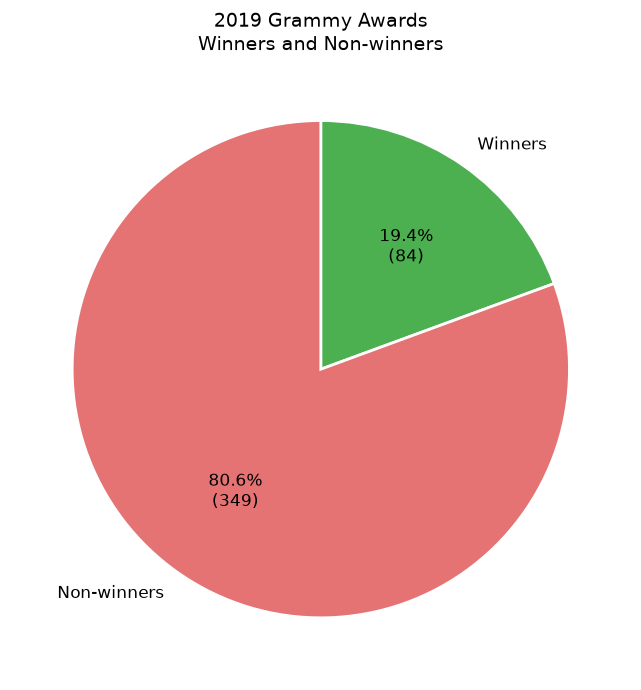

In [10]:
import matplotlib.pyplot as plt

# Select the corrected 2019 records.
grammy_2019 = cleaned_grammy[cleaned_grammy["year"] == 2019]

# Count winner and non-winner records.
counts = grammy_2019["winner"].value_counts().reindex([True, False], fill_value=0)

labels = ["Winners", "Non-winners"]
values = [counts[True], counts[False]]
colors = ["#4CAF50", "#E57373"]

# Plot the winner/non-winner distribution.
plt.figure(figsize=(7, 7))

plt.pie(
    values,
    labels=labels,
    colors=colors,
    autopct=lambda pct: f"{pct:.1f}%\n({int(round(pct / 100 * sum(values)))})",
    startangle=90,
    counterclock=False,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 12},
)

plt.title("2019 Grammy Awards\nWinners and Non-winners", fontsize=14)
plt.tight_layout()
plt.show()

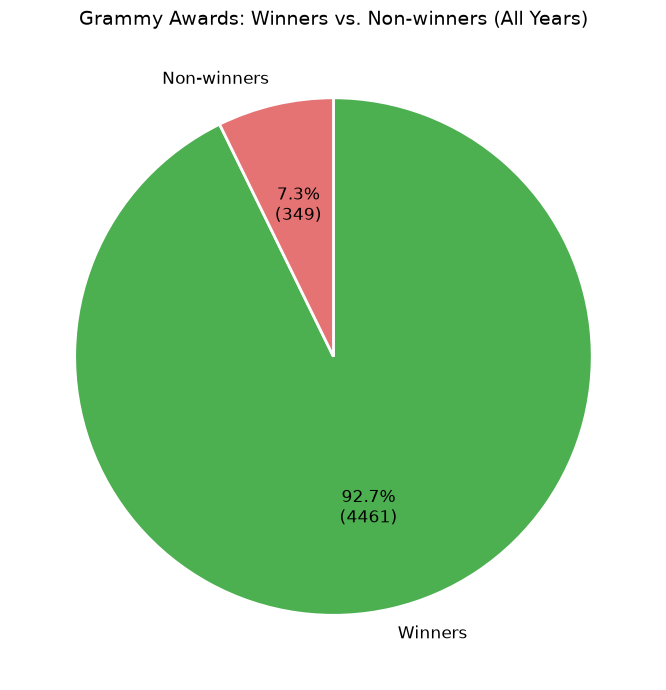

In [11]:
import matplotlib.pyplot as plt

# Use all years, without filtering
counts = cleaned_grammy["winner"].value_counts().reindex(
    [True, False], fill_value=0
)

labels = ["Winners", "Non-winners"]
values = [counts[True], counts[False]]
colors = ["#4CAF50", "#E57373"]

# Plot the winner/non-winner distribution
plt.figure(figsize=(7, 7))

plt.pie(
    values,
    labels=labels,
    colors=colors,
    autopct=lambda pct: f"{pct:.1f}%\n({int(round(pct / 100 * sum(values)))})",
    startangle=90,
    counterclock=False,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 12},
)

plt.title(
    "Grammy Awards: Winners vs. Non-winners (All Years)",
    fontsize=14
)

plt.tight_layout()
plt.show()

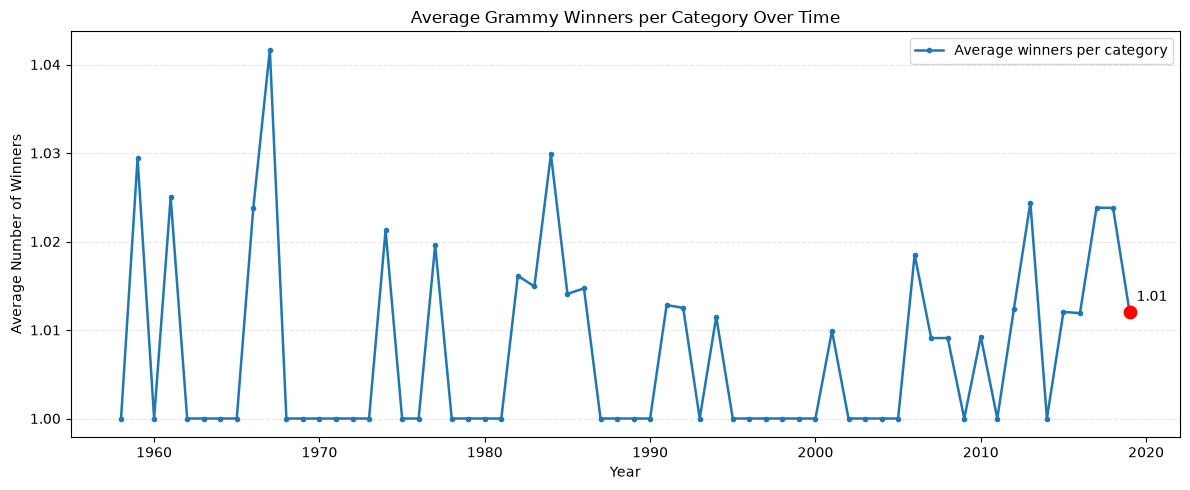

In [12]:
# Keep only winners
df = cleaned_grammy[cleaned_grammy["winner"] == True].copy()

# Count winners per category and year
entries_per_category = (
    df.groupby(["year", "category"])
    .size()
    .reset_index(name="num_winners")
)

# Calculate average winners per category each year
yearly_stats = (
    entries_per_category
    .groupby("year")["num_winners"]
    .mean()
    .reset_index(name="average_winners")
    .sort_values("year")
)

# Create a simple line chart
plt.figure(figsize=(12, 5))

plt.plot(
    yearly_stats["year"],
    yearly_stats["average_winners"],
    marker="o",
    linewidth=1.8,
    markersize=3,
    label="Average winners per category"
)

# Highlight 2019
year_2019 = yearly_stats[yearly_stats["year"] == 2019]

if not year_2019.empty:
    x = year_2019["year"].iloc[0]
    y = year_2019["average_winners"].iloc[0]

    plt.scatter(x, y, s=80, color="red", zorder=3)
    plt.annotate(
        f"{y:.2f}",
        (x, y),
        xytext=(5, 8),
        textcoords="offset points"
    )

plt.title("Average Grammy Winners per Category Over Time")
plt.xlabel("Year")
plt.ylabel("Average Number of Winners")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [13]:
# Use the cleaned dataset in memory instead of reading a generated CSV.
df = cleaned_grammy.copy()


In [14]:
# Inspect the in-memory cleaned Grammy dataset.
print(f"Cleaned Grammy dataset shape: {cleaned_grammy.shape}")
print("-" * 50)
cleaned_grammy.info()


Cleaned Grammy dataset shape: (4810, 10)
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4810 entries, 0 to 4809
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   year          4810 non-null   int64 
 1   title         4810 non-null   object
 2   published_at  4810 non-null   object
 3   updated_at    4810 non-null   object
 4   category      4810 non-null   object
 5   nominee       4804 non-null   object
 6   artist        2970 non-null   object
 7   workers       2620 non-null   object
 8   img           3443 non-null   object
 9   winner        4810 non-null   bool  
dtypes: bool(1), int64(1), object(8)
memory usage: 343.0+ KB


In [15]:
# Drop only rows where 'nominee' is null
cleaned_grammy = cleaned_grammy.dropna(subset=['nominee']).copy()

In [16]:
cleaned_grammy.isnull().sum()

year               0
title              0
published_at       0
updated_at         0
category           0
nominee            0
artist          1834
workers         2184
img             1361
winner             0
dtype: int64

In [17]:
import pandas as pd

artist_empty = cleaned_grammy['artist'].isna() | (cleaned_grammy['artist'].astype(str).str.strip() == '')
workers_empty = cleaned_grammy['workers'].isna() | (cleaned_grammy['workers'].astype(str).str.strip() == '')

missing = cleaned_grammy[artist_empty & workers_empty]

missing_by_category = (
    missing
    .groupby('category')
    .agg(
        frequency=('category', 'size'),
        first_year=('year', 'min'),
        last_year=('year', 'max'),
    )
    .sort_values('frequency', ascending=False)
    .reset_index()
)

missing_by_category

,category,frequency,first_year,last_year
0,Best New Artist,50,1965,2019
1,"Producer Of The Year, Non-Classical",22,1997,2018
2,"Producer Of The Year, Classical",22,1997,2018
3,Classical Producer Of The Year,18,1979,1996
4,Producer Of The Year,10,1977,1996
5,Producer Of The Year (Non-Classical),10,1980,1992
6,Best New Artist Of The Year,9,1968,1977
7,Best Classical Vocal Soloist Performance,7,1970,1987
8,Best Classical Vocal Performance,4,1992,1997
9,Best Classical Performance - Instrumental Solo...,4,1966,1986


In [18]:


# Count actual NaN
print("artist is NaN:", df['artist'].isna().sum())
print("workers is NaN:", df['workers'].isna().sum())
print()

# Count empty strings
print("artist is empty string:", (df['artist'].astype(str).str.strip() == '').sum())
print("workers is empty string:", (df['workers'].astype(str).str.strip() == '').sum())
print()

# Count whitespace-only strings
print("artist is whitespace:", (df['artist'].astype(str).str.strip().str.len() == 0).sum())
print("workers is whitespace:", (df['workers'].astype(str).str.strip().str.len() == 0).sum())

artist is NaN: 1840
workers is NaN: 2190

artist is empty string: 0
workers is empty string: 0

artist is whitespace: 0
workers is whitespace: 0


In [19]:
both_null = df[df['artist'].isna() & df['workers'].isna()]
print(f"Rows with BOTH artist and workers null: {len(both_null)}")
print()
print("Categories:")
print(both_null['category'].value_counts().to_string())

Rows with BOTH artist and workers null: 186

Categories:
category
Best New Artist                                                                              50
Producer Of The Year, Non-Classical                                                          22
Producer Of The Year, Classical                                                              22
Classical Producer Of The Year                                                               18
Producer Of The Year                                                                         10
Producer Of The Year (Non-Classical)                                                         10
Best New Artist Of The Year                                                                   9
Best Classical Vocal Soloist Performance                                                      7
Best Classical Vocal Performance                                                              4
Best Classical Performance - Instrumental Soloist Or Soloists (With Or

In [20]:
def is_empty(x):
    return pd.isna(x) or str(x).strip() == ''

df = df[
    ~(df['workers'].apply(is_empty) & df['artist'].apply(is_empty))
].copy()

In [21]:
import pandas as pd


# Normalize nulls
def is_empty(x):
    return pd.isna(x) or str(x).strip() == ''

# Case 1: artist has value
case1 = df[~df['artist'].apply(is_empty)]

# Case 2: artist null but workers has (...)
case2 = df[
    df['artist'].apply(is_empty) & 
    df['workers'].apply(lambda x: not is_empty(x) and '(' in str(x))
]

# Case 3: artist null, workers not null, but NO parentheses
case3 = df[
    df['artist'].apply(is_empty) & 
    df['workers'].apply(lambda x: not is_empty(x) and '(' not in str(x))
]

# Case 4: artist null AND workers null
case4 = df[
    df['artist'].apply(is_empty) & 
    df['workers'].apply(is_empty)
]

print(f"Case 1 (artist has value)         : {len(case1):5d}")
print(f"Case 2 (artist null + workers ()) : {len(case2):5d}")
print(f"Case 3 (artist null + workers wo) : {len(case3):5d}")
print(f"Case 4 (artist null + workers null): {len(case4):5d}")
print("-" * 45)
print(f"TOTAL                              : {len(df):5d}")

Case 1 (artist has value)         :  2970
Case 2 (artist null + workers ()) :  1366
Case 3 (artist null + workers wo) :   288
Case 4 (artist null + workers null):     0
---------------------------------------------
TOTAL                              :  4624


In [22]:
import re
import pandas as pd


def resolve_artist_final(row):
  artist = row['artist']
  workers = row['workers']
  nominee = row['nominee']

  # 1. If artist has a value, use it.
  if not pd.isna(artist) and str(artist).strip() != '':
    return str(artist).strip()

  # 2. If workers has a value, look for the artist's name there.
  if not pd.isna(workers) and str(workers).strip() != '':
    workers_str = str(workers).strip()

    # Highest priority: look for parentheses at the end (e.g., "... songwriters (Lady Gaga)")
    # or any parentheses containing the main artist's name.
    matches = re.findall(r'\(([^)]+)\)', workers_str)
    if matches:
      # The last parenthetical usually contains the artist, e.g., Lady Gaga.
      candidate = matches[-1].strip()
      # Make sure it is not a generic technical role.
      if candidate.lower() not in [
          'producer',
          'songwriter',
          'songwriters',
          'engineer',
          'mixers',
      ]:
        return candidate

    # If there are no parentheses, take the first part before a comma or semicolon.
    first_part = re.split(r'[,;]', workers_str)[0].strip()
    # Remove any standalone words if needed.
    return first_part

  # 3. If all else fails, fall back to nominee (although in songwriting, nominee is the song;
  # this fallback is still useful when no other information is available).
  if not pd.isna(nominee) and str(nominee).strip() != '':
    return str(nominee).strip()

  return None


# Apply the function to the DataFrame.
df['artist_resolved'] = df.apply(resolve_artist_final, axis=1)

# Check how many null values remain.
print(
    f"Null values remaining in artist_resolved:"
    f" {df['artist_resolved'].isna().sum()}"
)

Null values remaining in artist_resolved: 0


In [23]:
# Count null values in artist_resolved
print("Null values in artist_resolved:")
print(df['artist_resolved'].isna().sum())

# Display rows where artist_resolved is null
null_artists = df[df['artist_resolved'].isna()]

print(f"\nRows with unresolved artists: {len(null_artists)}")

print(
    null_artists[
        ['artist', 'workers', 'nominee', 'artist_resolved']
    ].head(20).to_string(index=False)
)

Null values in artist_resolved:
0

Rows with unresolved artists: 0
Empty DataFrame
Columns: [artist, workers, nominee, artist_resolved]
Index: []


In [24]:
import pandas as pd

# 1. Check the total number of rows
total_rows = len(df)

# 2. Count unresolved or potentially unresolved artists
unknown_count = (
    df['artist_resolved']
    .astype('string')
    .str.strip()
    .str.lower()
    .eq('desconocido')
    .sum()
)

null_count = df['artist_resolved'].isna().sum()

empty_count = (
    df['artist_resolved']
    .astype('string')
    .str.strip()
    .eq('')
    .sum()
)

# 3. Count resolved artists
unresolved_count = unknown_count + null_count + empty_count
resolved_count = total_rows - unresolved_count

resolution_rate = (
    resolved_count / total_rows * 100
    if total_rows > 0 else 0
)

# 4. Display the results
print("ARTIST RESOLUTION VALIDATION")
print("-" * 45)
print(f"Total rows: {total_rows}")
print(f"Resolved rows: {resolved_count}")
print(f"Unresolved rows: {unresolved_count}")
print(f"  - Unknown: {unknown_count}")
print(f"  - Null: {null_count}")
print(f"  - Empty: {empty_count}")
print(f"Resolution rate: {resolution_rate:.2f}%")

# 5. Show rows that still need attention
review_df = df[
    df['artist_resolved'].isna()
    | df['artist_resolved'].astype('string').str.strip().eq('')
    | df['artist_resolved'].astype('string').str.strip().str.lower().eq('desconocido')
]

print("\nROWS REQUIRING REVIEW")
print("-" * 45)

if review_df.empty:
    print("No unresolved rows found.")
else:
    print(
        review_df[
            ['artist', 'workers', 'nominee', 'artist_resolved']
        ].head(20).to_string(index=False)
    )


ARTIST RESOLUTION VALIDATION
---------------------------------------------
Total rows: 4624
Resolved rows: 4624
Unresolved rows: 0
  - Unknown: 0
  - Null: 0
  - Empty: 0
Resolution rate: 100.00%

ROWS REQUIRING REVIEW
---------------------------------------------
No unresolved rows found.


In [25]:
# ==========================================
# DIRECT CLASSIFICATION USING THE CURRENT DATAFRAME
# ==========================================


def classify_grammy(category_str):
  cat_lower = str(category_str).lower()

  # If the category is for albums.
  if 'album' in cat_lower:
    return 'album'
  # If the category is for songs, singles, or performances.
  elif any(
      term in cat_lower
      for term in [
          'song',
          'record of the year',
          'performance',
          'solo',
          'duo',
          'group',
          'collaboration',
          'composition',
      ]
  ):
    return 'song'
  # Everything else (videos, packaging, liner notes, etc.).
  else:
    return 'other'


# Create the classification column in the current DataFrame.
df['grammy_type'] = df['category'].apply(classify_grammy)

# Split the data into three independent subsets.
df_songs = df[df['grammy_type'] == 'song'].copy()
df_albums = df[df['grammy_type'] == 'album'].copy()
df_other = df[df['grammy_type'] == 'other'].copy()

# Summarize the number of records in each group.
print('=== CLASSIFICATION SUMMARY ===')
print(f'Total rows in df: {len(df)}')
print(df['grammy_type'].value_counts())

=== CLASSIFICATION SUMMARY ===
Total rows in df: 4624
grammy_type
song     2282
album    1610
other     732
Name: count, dtype: int64


In [26]:
# ==========================================
# FILTER TO KEEP SONGS ONLY
# ==========================================

# Filter the DataFrame to retain only songs.
df_songs_only = df[df['grammy_type'] == 'song'].copy()

# Verify the filtered result.
print('=== FILTERING COMPLETE ===')
print(f'Original rows in df: {len(df)}')
print(f'Rows retained (songs only): {len(df_songs_only)}')
print(
    'Current distribution:',
    df_songs_only['grammy_type'].value_counts().to_dict(),
)

# Optional: Set the main 'df' variable to contain songs only.
# df = df_songs_only.copy()

=== FILTERING COMPLETE ===
Original rows in df: 4624
Rows retained (songs only): 2282
Current distribution: {'song': 2282}


In [27]:
print(f"Dataset size: {df_songs_only.shape[0]} rows × {df_songs_only.shape[1]} columns")

Dataset size: 2282 rows × 12 columns


In [28]:
# ==========================================
# FILTER FOR SONGS THAT WON
# ==========================================

# Keep only songs (grammy_type == 'song') that are winners (winner == True).
df_song_winners = df[
    (df['grammy_type'] == 'song') & (df['winner'] == True)
].copy()

# Verify the results.
print('=== WINNING SONGS FILTERED ===')
print(f'Total winning songs: {len(df_song_winners)}')

# Display a small sample for verification.
print(
    df_song_winners[
        ['year', 'title', 'category', 'nominee', 'artist_resolved', 'winner']
    ]
    .head(5)
    .to_string(index=False)
)

# Keep only the columns required for the exported dataset.
df_song_winners = df_song_winners[
    ['year', 'title', 'category', 'nominee', 'artist_resolved']
].copy()

# Verify the cleaned dataset.
df_song_winners.info()
print(df_song_winners.head())

# Export the filtered dataset to the requested folder.
output_path = '/home/sebastiancelorio.dev/Projects/data-engineering/spotify-grammys-etl/notebooks/grammys/TestDataset/grammys_song_winners.csv'
df_song_winners.to_csv(output_path, index=False)
print(f'CSV exported to: {output_path}')


=== WINNING SONGS FILTERED ===
Total winning songs: 2163
 year                             title                       category       nominee                     artist_resolved  winner
 2019 62nd Annual GRAMMY Awards  (2019)             Record Of The Year       Bad Guy                       Billie Eilish    True
 2019 62nd Annual GRAMMY Awards  (2019)               Song Of The Year       Bad Guy                       Billie Eilish    True
 2019 62nd Annual GRAMMY Awards  (2019)      Best Pop Solo Performance   Truth Hurts                               Lizzo    True
 2019 62nd Annual GRAMMY Awards  (2019) Best Pop Duo/Group Performance Old Town Road Lil Nas X Featuring Billy Ray Cyrus    True
 2019 62nd Annual GRAMMY Awards  (2019)          Best Rock Performance     This Land                      Gary Clark Jr.    True
CSV exported to: /home/sebastiancelorio.dev/Projects/data-engineering/spotify-grammys-etl/notebooks/grammys/TestDataset/grammys_song_winners.csv


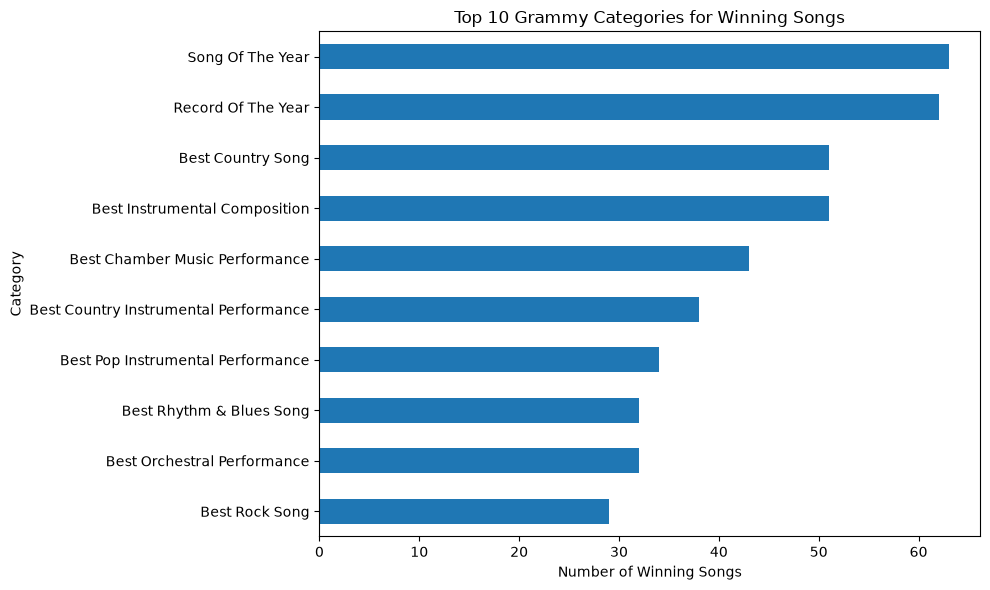

In [29]:
import matplotlib.pyplot as plt

category_counts = df_song_winners['category'].value_counts().head(10)

category_counts.sort_values().plot(kind='barh', figsize=(10, 6))

plt.title('Top 10 Grammy Categories for Winning Songs')
plt.xlabel('Number of Winning Songs')
plt.ylabel('Category')
plt.tight_layout()
plt.show()

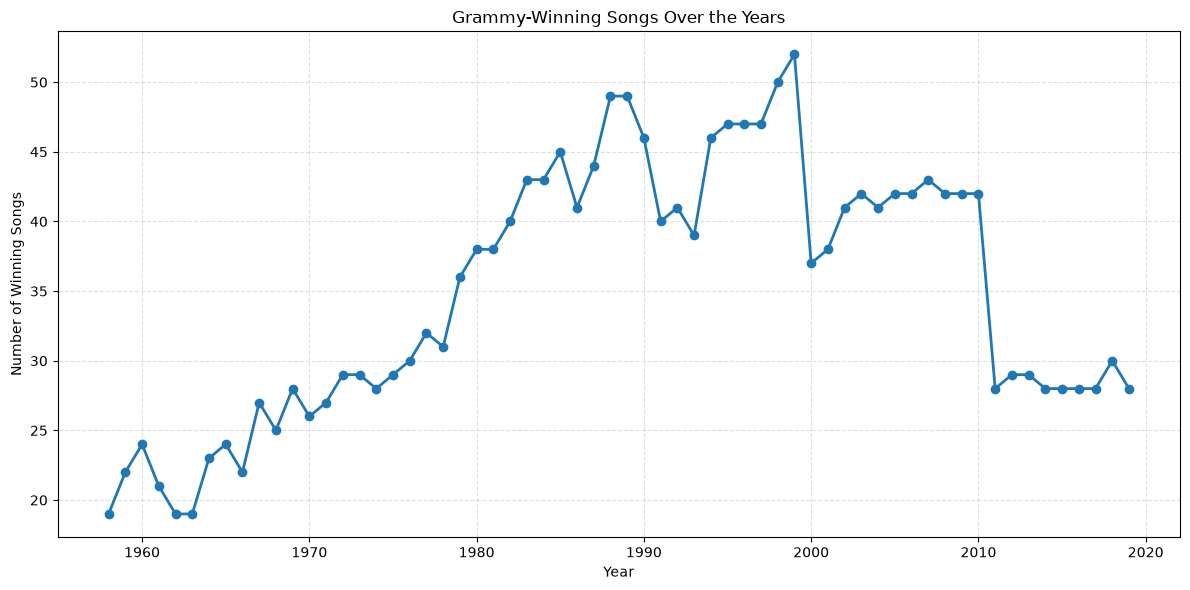

In [31]:
import matplotlib.pyplot as plt

# Count winning songs by year.
winners_by_year = df_song_winners.groupby('year').size()

# Create the line chart.
plt.figure(figsize=(12, 6))

plt.plot(
    winners_by_year.index,
    winners_by_year.values,
    marker='o',
    linewidth=2
)

plt.title('Grammy-Winning Songs Over the Years')
plt.xlabel('Year')
plt.ylabel('Number of Winning Songs')
plt.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

In [33]:
# Calculate the average number of winning songs per category per year.
avg_winners_by_category_year = (
    df_song_winners.groupby(['category', 'year'])
    .size()
    .groupby('category')
    .mean()
    .sort_values(ascending=False)
)

print('=== AVERAGE WINNING SONGS PER CATEGORY PER YEAR ===')
print(avg_winners_by_category_year.round(2))

=== AVERAGE WINNING SONGS PER CATEGORY PER YEAR ===
category
Best Classical Choral Performance (Other Than Opera)              1.67
Best Contemporary Christian Music Song                            1.33
Best Traditional R&B Performance                                  1.11
Best Contemporary Classical Composition                           1.11
Best Gospel Performance                                           1.10
                                                                  ... 
Best Country Solo Performance                                     1.00
Best Country Performance, Duo Or Group - Vocal Or Instrumental    1.00
Best Country Performance Duo Or Group                             1.00
Best Country Performance By A Duo Or Group With Vocals            1.00
Best Country Vocal Solo Performance, Male                         1.00
Length: 344, dtype: float64
